# Big Data con PySpark y MLlib: Steam Reviews

**Base de datos:** Steam Reviews Dataset 2021 (Kaggle). Son aproximadamente 21 millones de reseñas de videojuegos de la plataforma Steam, en un CSV de varios GB.

**Problema:** predecir si una reseña **recomienda** el juego (`recommended` = 1) o **no** (0), a partir del perfil del jugador (horas jugadas, juegos que posee, número de reseñas) y de características de la reseña (longitud, compra en Steam, juego gratis, acceso anticipado, idioma).

## 1. Configuración del entorno de trabajo (PySpark en Colab)

Instalamos Java (requisito de Spark) y PySpark, y creamos la `SparkSession`.

In [ ]:
# Instalar Java 17 y PySpark
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark==3.5.1 kaggle

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import os
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-17-openjdk-amd64'

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName('Steam_Reviews_MLlib')
         .master('local[*]')
         .config('spark.driver.memory', '5g')
         .config('spark.sql.shuffle.partitions', '16')
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

print('Versión de Spark:', spark.version)
print('Núcleos disponibles:', spark.sparkContext.defaultParallelism)

Versión de Spark: 3.5.1
Núcleos disponibles: 2


## 2. Descarga de datos y conversión a Parquet

### 2.1 Descargar el dataset desde Kaggle

In [ ]:
# Nombre del dataset en Kaggle (usuario/dataset). Ajusta si es necesario.
DATASET = 'najzeko/steam-reviews-2021'

!kaggle datasets download -d $DATASET -p /content/steam --unzip
!ls -lh /content/steam

Dataset URL: https://www.kaggle.com/datasets/najzeko/steam-reviews-2021
License(s): GPL-2.0
100% 2.97G/2.97G [00:40<00:00, 78.8MB/s]

total 7.7G
-rw-r--r-- 1 root root 7.7G Nov 23 15:52 steam_reviews.csv


In [ ]:
import glob
import pandas as pd

csv_path = max(glob.glob('/content/steam/**/*.csv', recursive=True), key=os.path.getsize)
print('Archivo:', csv_path)
print('Tamaño : {:.2f} GB'.format(os.path.getsize(csv_path) / 1e9))

header = pd.read_csv(csv_path, nrows=0).columns.tolist()
print('Columnas ({}):'.format(len(header)))
print(header)

Archivo: /content/steam/steam_reviews.csv
Tamaño : 8.17 GB
Columnas (23):
['Unnamed: 0', 'app_id', 'app_name', 'review_id', 'language', 'review', 'timestamp_created', 'timestamp_updated', 'recommended', 'votes_helpful', 'votes_funny', 'weighted_vote_score', 'comment_count', 'steam_purchase', 'received_for_free', 'written_during_early_access', 'author.steamid', 'author.num_games_owned', 'author.num_reviews', 'author.playtime_forever', 'author.playtime_last_two_weeks', 'author.playtime_at_review', 'author.last_played']


### 2.2 Convertir el CSV a Parquet

Las reseñas de Steam contienen texto con saltos de línea y comillas, lo que hace que el CSV sea muy lento de leer directamente con Spark (el modo `multiLine` impide dividir el archivo entre núcleos).

Por eso hacemos una conversión **una sola vez**: leemos el CSV por bloques con pandas, nos quedamos con las columnas necesarias, calculamos la longitud de cada reseña (`review_len`) y guardamos el resultado en **Parquet**, un formato columnar mucho más rápido y compacto para Spark. Se conservan los ~21 millones de registros.

In [ ]:
import shutil

# Columnas originales -> nombres simples
rename = {
    'app_id': 'app_id',
    'app_name': 'app_name',
    'language': 'language',
    'timestamp_created': 'timestamp_created',
    'recommended': 'recommended',
    'votes_helpful': 'votes_helpful',
    'votes_funny': 'votes_funny',
    'steam_purchase': 'steam_purchase',
    'received_for_free': 'received_for_free',
    'written_during_early_access': 'early_access',
    'author.num_games_owned': 'num_games_owned',
    'author.num_reviews': 'num_reviews',
    'author.playtime_forever': 'playtime_forever',
    'author.playtime_at_review': 'playtime_at_review'
}
needed = list(rename.keys()) + ['review']
missing = [c for c in needed if c not in header]
if missing:
    raise ValueError('No se encontraron estas columnas en el CSV: ' + ', '.join(missing) +
                     '. Revisa la lista de columnas de la celda anterior y ajusta el diccionario rename.')

bool_cols = ['recommended', 'steam_purchase', 'received_for_free', 'early_access']
num_cols = ['app_id', 'timestamp_created', 'votes_helpful', 'votes_funny', 'num_games_owned',
            'num_reviews', 'playtime_forever', 'playtime_at_review']

out_dir = '/content/steam_parquet'
shutil.rmtree(out_dir, ignore_errors=True)
os.makedirs(out_dir)

reader = pd.read_csv(csv_path, usecols=needed, chunksize=250000, on_bad_lines='skip')
total = 0
for i, chunk in enumerate(reader):
    chunk['review_len'] = chunk['review'].fillna('').astype(str).str.len()
    chunk = chunk.drop(columns=['review']).rename(columns=rename)
    for c in bool_cols:
        chunk[c] = chunk[c].astype(str).str.lower().eq('true').astype('int8')
    for c in num_cols:
        chunk[c] = pd.to_numeric(chunk[c], errors='coerce')
    chunk['app_name'] = chunk['app_name'].astype(str)
    chunk['language'] = chunk['language'].astype(str)
    chunk.to_parquet('{}/part_{:04d}.parquet'.format(out_dir, i), index=False)
    total += len(chunk)
    if i % 10 == 0:
        print('Bloque {} procesado | filas acumuladas: {:,}'.format(i, total))

print('Conversión terminada. Filas totales:', f'{total:,}')
!du -sh /content/steam_parquet

Bloque 0 procesado | filas acumuladas: 250,000
Bloque 10 procesado | filas acumuladas: 2,750,000
Bloque 20 procesado | filas acumuladas: 5,250,000
Bloque 30 procesado | filas acumuladas: 7,750,000
Bloque 40 procesado | filas acumuladas: 10,250,000
Bloque 50 procesado | filas acumuladas: 12,750,000
Bloque 60 procesado | filas acumuladas: 15,250,000
Bloque 70 procesado | filas acumuladas: 17,750,000
Bloque 80 procesado | filas acumuladas: 20,250,000
Conversión terminada. Filas totales: 21,747,371
352M	/content/steam_parquet


## 3. Carga, limpieza y exploración con Spark

A partir de aquí todo el procesamiento se hace con PySpark.

In [ ]:
from pyspark.sql import functions as F

tipos = {
    'app_id': 'int', 'app_name': 'string', 'language': 'string', 'timestamp_created': 'long',
    'recommended': 'int', 'votes_helpful': 'int', 'votes_funny': 'int',
    'steam_purchase': 'int', 'received_for_free': 'int', 'early_access': 'int',
    'num_games_owned': 'double', 'num_reviews': 'double',
    'playtime_forever': 'double', 'playtime_at_review': 'double', 'review_len': 'int'
}

raw = spark.read.parquet('/content/steam_parquet')
raw = raw.select([F.col(c).cast(t).alias(c) for c, t in tipos.items()])

n_crudo = raw.count()
print('Número de registros (crudos):', f'{n_crudo:,}')
print('Número de columnas:', len(raw.columns))
raw.printSchema()
raw.show(5, truncate=40)

Número de registros (crudos): 21,747,371
Número de columnas: 15
root
 |-- app_id: integer (nullable = true)
 |-- app_name: string (nullable = true)
 |-- language: string (nullable = true)
 |-- timestamp_created: long (nullable = true)
 |-- recommended: integer (nullable = true)
 |-- votes_helpful: integer (nullable = true)
 |-- votes_funny: integer (nullable = true)
 |-- steam_purchase: integer (nullable = true)
 |-- received_for_free: integer (nullable = true)
 |-- early_access: integer (nullable = true)
 |-- num_games_owned: double (nullable = true)
 |-- num_reviews: double (nullable = true)
 |-- playtime_forever: double (nullable = true)
 |-- playtime_at_review: double (nullable = true)
 |-- review_len: integer (nullable = true)

+------+--------+--------+-----------------+-----------+-------------+-----------+--------------+-----------------+------------+---------------+-----------+----------------+------------------+----------+
|app_id|app_name|language|timestamp_created|recommend

In [ ]:
# Estadísticas descriptivas de los datos crudos
raw.select('playtime_at_review', 'playtime_forever', 'num_games_owned', 'num_reviews', 'review_len').describe().show()

+-------+------------------+-----------------+-------------------+--------------------+-----------------+
|summary|playtime_at_review| playtime_forever|    num_games_owned|         num_reviews|       review_len|
+-------+------------------+-----------------+-------------------+--------------------+-----------------+
|  count|          21721689|         21747369|           21747371|            21747371|         21747371|
|   mean| 8807.421419761604|16091.04968789558| 1011300.0967205645|   404477.4800190791|170.2928924604266|
| stddev|23885.530542758777|37430.56775904516|2.108829161096281E9|1.3337407610248506E9|4646.150986957336|
|    min|               1.0|              0.0|                0.0|                 1.0|                0|
|    max|         3228103.0|        3744943.0|  4.398046511619E12|   4.398046511108E12|          9639004|
+-------+------------------+-----------------+-------------------+--------------------+-----------------+



**Interpretación de las estadísticas crudas**

- **Sesgo fuerte a la derecha.** Las horas al reseñar promedian 8,807 min (≈147 h), pero la desviación estándar es de 23,886 min: pocos jugadores con miles de horas jalan el promedio. Es la razón de aplicar `log1p` a las variables de conteo y tiempo.
- **Valores imposibles en `num_games_owned` y `num_reviews`.** Ambas llegan a ≈4.4 × 10¹², casi exactamente 2⁴² (4,398,046,511,104). Ninguna cuenta de Steam tiene ese número de juegos; el patrón sugiere un error de codificación en la fuente. Por eso sus promedios (1,011,300 juegos y 404,477 reseñas) no describen a ningún jugador real.
- **`review_len` tiene un máximo de 9.6 millones de caracteres** contra una media de 170: unas cuantas reseñas gigantes (texto pegado o spam) distorsionan el promedio.
- **La limpieza solo quitó nulos.** `playtime_at_review` tiene 25,682 nulos y `playtime_forever` 2 más, que suman exactamente los 25,684 descartados (0.1%). Los valores atípicos siguen en los datos; por eso en la sección 7.1 se usan medianas.
- **Impacto real de los atípicos: muy pocos registros.** Solo 5 registros tienen más de 50,000 juegos, 2 tienen más de 50,000 reseñas escritas, 55 tienen reseñas de más de 50,000 caracteres y 2 superan las 50,000 horas (de 21.7 millones). Distorsionan los promedios, pero no a la mayoría de los datos (ver 7.1, celda A).


### 3.1 Limpieza e ingeniería de variables

In [ ]:
def add_features(df):
    return (df
        .withColumn('log_playtime_review', F.log1p('playtime_at_review'))
        .withColumn('log_playtime_forever', F.log1p('playtime_forever'))
        .withColumn('log_games_owned', F.log1p('num_games_owned'))
        .withColumn('log_num_reviews', F.log1p('num_reviews'))
        .withColumn('log_review_len', F.log1p(F.col('review_len').cast('double')))
        .withColumn('is_english', F.when(F.col('language') == 'english', 1).otherwise(0)))

def clean(df):
    d = (df
        .dropna(subset=['app_id', 'recommended', 'playtime_at_review', 'playtime_forever',
                        'num_games_owned', 'num_reviews', 'review_len'])
        .filter(F.col('recommended').isin(0, 1))
        .filter((F.col('playtime_at_review') >= 0) & (F.col('playtime_forever') >= 0))
        .filter((F.col('num_games_owned') >= 0) & (F.col('num_reviews') >= 0))
        .withColumn('label', F.col('recommended').cast('double'))
        .withColumn('review_date', F.to_date(F.from_unixtime('timestamp_created')))
        .withColumn('review_month', F.date_format('review_date', 'yyyy-MM')))
    return add_features(d)

df = clean(raw).cache()
n_limpio = df.count()
print('Registros crudos :', f'{n_crudo:,}')
print('Registros limpios:', f'{n_limpio:,}')
print('Descartados      :', f'{n_crudo - n_limpio:,}', '({:.1f}%)'.format(100 * (n_crudo - n_limpio) / n_crudo))

Registros crudos : 21,747,371
Registros limpios: 21,721,687
Descartados      : 25,684 (0.1%)


   label     count    pct
0    0.0   2720231  12.52
1    1.0  19001456  87.48


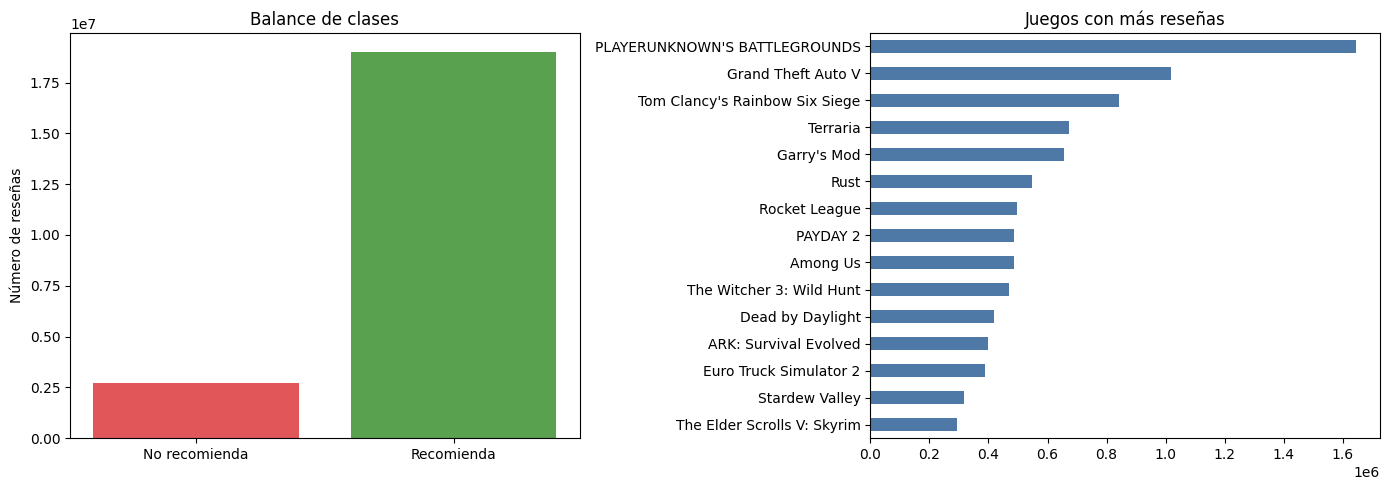

In [ ]:
import matplotlib.pyplot as plt

# Balance de clases
balance = df.groupBy('label').count().orderBy('label').toPandas()
balance['pct'] = (100 * balance['count'] / balance['count'].sum()).round(2)
print(balance)

# Juegos con más reseñas y su % de recomendación
top_juegos = (df.groupBy('app_name')
                .agg(F.count('*').alias('reseñas'), (100 * F.avg('label')).alias('pct_recomendado'))
                .orderBy(F.desc('reseñas')).limit(15).toPandas())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(['No recomienda', 'Recomienda'], balance['count'], color=['#e15759', '#59a14f'])
ax[0].set_title('Balance de clases')
ax[0].set_ylabel('Número de reseñas')
top_juegos.sort_values('reseñas').plot.barh(x='app_name', y='reseñas', ax=ax[1], legend=False, color='#4e79a7')
ax[1].set_title('Juegos con más reseñas')
ax[1].set_ylabel('')
plt.tight_layout()
plt.show()

**Interpretación del balance de clases y de los juegos más reseñados**

- **Desbalance de ≈7 a 1** (87.5% recomienda, 12.5% no). Un modelo que siempre respondiera "recomienda" tendría 87.5% de accuracy sin aprender nada, por lo que el accuracy es una métrica engañosa aquí. Esto justifica los pesos por clase y el uso de AUC-ROC como métrica principal.
- **Concentración en pocos títulos.** PUBG supera 1.6 millones de reseñas y, junto con GTA V y Rainbow Six Siege, reúne aproximadamente 16% del total. El modelo aprende, por tanto, sobre todo de unos pocos juegos, y puede asimilar rasgos propios de ellos. Este riesgo es el que motiva el conjunto de juegos nuevos (holdout) de la sección 7.
- **Predominan los juegos multijugador y en línea** (PUBG, Rainbow Six, Rust, Among Us, Dead by Daylight, Rocket League), junto con sandbox (Terraria, Garry's Mod). Son juegos con muchas horas por jugador, lo que ayuda a entender por qué las horas pesan tanto en el modelo.
- **Limitación de la gráfica:** muestra volumen de reseñas, no satisfacción. Un juego muy reseñado puede ser muy bien o muy mal valorado; el porcentaje de recomendación por juego se calcula en 7.1 y en el tablero.

In [ ]:
# Comparación de promedios entre quienes recomiendan y quienes no
(df.groupBy('label')
   .agg(F.round(F.avg('playtime_at_review') / 60, 1).alias('horas_al_reseñar'),
        F.round(F.avg('playtime_forever') / 60, 1).alias('horas_totales'),
        F.round(F.avg('num_games_owned'), 1).alias('juegos_que_posee'),
        F.round(F.avg('review_len'), 1).alias('long_reseña_caracteres'),
        F.round(100 * F.avg('is_english'), 1).alias('pct_ingles'))
   .orderBy('label')
   .show())

+-----+----------------+-------------+----------------+----------------------+----------+
|label|horas_al_reseñar|horas_totales|juegos_que_posee|long_reseña_caracteres|pct_ingles|
+-----+----------------+-------------+----------------+----------------------+----------+
|  0.0|           202.3|        331.0|           139.6|                 267.1|      38.6|
|  1.0|           138.9|        259.4|       1157423.6|                 156.4|      45.1|
+-----+----------------+-------------+----------------+----------------------+----------+



**Interpretación de la comparación entre quienes recomiendan y quienes no**

Los promedios de esta tabla están inflados por unos cuantos jugadores extremos, así que conviene leerlos junto con las medianas de 7.1 (celda A), que son más confiables:

- **Horas jugadas:** quienes no recomiendan sí han jugado más, pero la diferencia es menor de lo que sugieren los promedios (+46% al reseñar). Con medianas es de ≈20%: 37.2 h contra 30.9 h al reseñar, y 78.9 h contra 71.3 h en total. Los críticos no son novatos que abandonan pronto; son jugadores con algo más de recorrido.
- **Longitud de la reseña:** esta diferencia sí es robusta. Las reseñas negativas son ≈70% más largas tanto en promedio (267.1 contra 156.4 caracteres) como en mediana (63 contra 37). Quien está inconforme tiende a explicar su queja.
- **Idioma:** el inglés pesa 45.1% entre las reseñas positivas y 38.6% entre las negativas, pero la diferencia no es de "los demás idiomas" en general: en 7.1 (celda C) el inglés y el ruso recomiendan alrededor de 89%, y quien baja el promedio es el chino simplificado (77.1%).
- **Biblioteca de juegos y reseñas escritas:** las medianas son casi iguales entre grupos (63 contra 60 juegos; 4 contra 4 reseñas). El promedio de 1,157,423 juegos de la clase positiva es un artefacto de 5 registros con valores imposibles y no debe interpretarse.


## 4. Modelos con MLlib

**Tipo de modelo:** clasificación binaria (`label`: 1 = recomienda, 0 = no recomienda).

**Variables predictoras:** `log_playtime_review`, `log_playtime_forever`, `log_games_owned`, `log_num_reviews`, `log_review_len`, `steam_purchase`, `received_for_free`, `early_access`, `is_english`.

No usamos votos de utilidad ni votos graciosos porque esos datos se generan después de publicar la reseña.

**Datos de prueba nuevos:** antes de dividir los datos, apartamos aproximadamente el 10% de los **juegos** (elegidos por azar con una función hash del `app_id`). Esas reseñas no se usan nunca en el entrenamiento ni en la evaluación principal. En la sección 7 las usamos para probar si el modelo funciona con juegos que no conoce.

**Desbalance de clases:** la mayoría de las reseñas son positivas. Para que el modelo no ignore a la clase minoritaria, usamos **pesos por clase** durante el entrenamiento (`weightCol`).

In [ ]:
# Apartar ~10% de los juegos como conjunto de datos completamente nuevo
es_holdout = (F.abs(F.hash('app_id')) % 10 == 0)
holdout = df.filter(es_holdout)
principal = df.filter(~es_holdout)

# Partición 80% entrenamiento / 20% prueba sobre el resto
train_full, test = principal.randomSplit([0.8, 0.2], seed=42)

# Para que el entrenamiento sea rápido en Colab usamos una fracción del conjunto de entrenamiento.
# Sube este valor hacia 1.0 si tu sesión tiene suficiente memoria y tiempo.
TRAIN_FRACTION = 0.15
train = train_full.sample(fraction=TRAIN_FRACTION, seed=42)

# Pesos por clase (inverso de la frecuencia)
conteo = train.groupBy('label').count().collect()
cuentas = {r['label']: r['count'] for r in conteo}
n_train = sum(cuentas.values())
peso = {k: n_train / (2.0 * v) for k, v in cuentas.items()}
print('Pesos por clase:', {k: round(v, 3) for k, v in peso.items()})

train = (train.withColumn('weight', F.when(F.col('label') == 1.0, peso[1.0]).otherwise(peso[0.0]))).cache()
test = test.cache()

print('Registros de entrenamiento:', f'{train.count():,}')
print('Registros de prueba       :', f'{test.count():,}')
print('Registros de juegos nuevos (holdout):', f'{holdout.count():,}')

Pesos por clase: {1.0: 0.578, 0.0: 3.719}
Registros de entrenamiento: 2,307,184
Registros de prueba       : 3,844,624
Registros de juegos nuevos (holdout): 2,505,860


In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

feature_cols = ['log_playtime_review', 'log_playtime_forever', 'log_games_owned', 'log_num_reviews',
                'log_review_len', 'steam_purchase', 'received_for_free', 'early_access', 'is_english']

assembler = VectorAssembler(inputCols=feature_cols, outputCol='features')
scaler = StandardScaler(inputCol='features', outputCol='features_scaled', withStd=True, withMean=False)

lr = LogisticRegression(featuresCol='features_scaled', labelCol='label', weightCol='weight', maxIter=50)
rf = RandomForestClassifier(featuresCol='features', labelCol='label', weightCol='weight',
                            numTrees=50, maxDepth=8, subsamplingRate=0.5, seed=42)

pipe_lr = Pipeline(stages=[assembler, scaler, lr])
pipe_rf = Pipeline(stages=[assembler, rf])

print('Entrenando Regresión Logística...')
model_lr = pipe_lr.fit(train)
print('Entrenando Random Forest (puede tardar varios minutos)...')
model_rf = pipe_rf.fit(train)
print('Listo.')

Entrenando Regresión Logística...
Entrenando Random Forest (puede tardar varios minutos)...
Listo.


## 5. Evaluación del modelo

Usamos evaluadores de PySpark sobre el conjunto de prueba (datos que el modelo no vio):
- **AUC-ROC:** capacidad de separar las dos clases (0.5 = azar, 1 = perfecto).
- **AUC-PR:** área bajo la curva precisión-recall; útil cuando hay desbalance.
- **Accuracy:** proporción de aciertos. Con clases desbalanceadas puede engañar.
- **F1 ponderado, precisión y recall ponderados.**

In [ ]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

def evaluate_clf(pred, name):
    res = {'modelo': name}
    for m in ['areaUnderROC', 'areaUnderPR']:
        ev = BinaryClassificationEvaluator(labelCol='label', rawPredictionCol='rawPrediction', metricName=m)
        res[m] = round(ev.evaluate(pred), 4)
    for m in ['accuracy', 'f1', 'weightedPrecision', 'weightedRecall']:
        ev = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName=m)
        res[m] = round(ev.evaluate(pred), 4)
    return res

pred_lr = model_lr.transform(test)
pred_rf = model_rf.transform(test).cache()

resultados = pd.DataFrame([evaluate_clf(pred_lr, 'Regresión Logística'),
                           evaluate_clf(pred_rf, 'Random Forest')])
resultados

,modelo,areaUnderROC,areaUnderPR,accuracy,f1,weightedPrecision,weightedRecall
0,Regresión Logística,0.6410,0.9137,0.6042,0.6671,0.8114,0.6042
1,Random Forest,0.7128,0.9339,0.6791,0.7278,0.8285,0.6791


In [ ]:
# Matriz de confusión del Random Forest (calculada en Spark)
cm = (pred_rf.groupBy('label', 'prediction').count().toPandas()
             .pivot(index='label', columns='prediction', values='count').fillna(0).astype(int))
cm.index = ['Real: No recomienda', 'Real: Recomienda']
cm.columns = ['Pred: No recomienda', 'Pred: Recomienda']
print(cm)

# Recall por clase
tn, fp = cm.iloc[0, 0], cm.iloc[0, 1]
fn, tp = cm.iloc[1, 0], cm.iloc[1, 1]
print('\nRecall clase No recomienda: {:.3f}'.format(tn / (tn + fp)))
print('Recall clase Recomienda   : {:.3f}'.format(tp / (tp + fn)))
print('Precisión clase No recomienda: {:.3f}'.format(tn / (tn + fn)))
print('Precisión clase Recomienda   : {:.3f}'.format(tp / (tp + fp)))

                     Pred: No recomienda  Pred: Recomienda
Real: No recomienda               318369            197945
Real: Recomienda                 1035947           2292363

Recall clase No recomienda: 0.617
Recall clase Recomienda   : 0.689
Precisión clase No recomienda: 0.235
Precisión clase Recomienda   : 0.921


**Interpretación de la matriz de confusión**

- En la prueba hay 516,314 reseñas realmente negativas (13.4% de 3,844,624). El modelo marca 1,354,316 como "no recomienda", pero solo **23.5% de ellas lo son**. Frente a la tasa base de 13.4%, eso es un **lift de ≈1.75×**: mejor que el azar, pero lejos de ser una clasificación confiable.
- El modelo **detecta 61.7% de las negativas reales**, a costa de marcar erróneamente como negativas **31.1% de las positivas** (1,035,947 de 3,328,310). Esos falsos negativos son el error dominante.
- **Uso razonable:** como filtro de priorización (por ejemplo, revisar primero las reseñas con mayor riesgo de ser negativas), no como decisión automática. La sección 7.1 (celda F) evalúa cómo cambian precisión y recall al mover el umbral de 0.5.

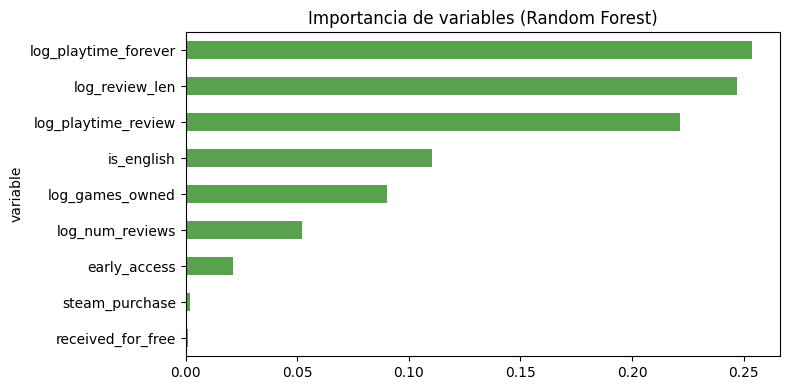

Coeficientes de la Regresión Logística (variables escaladas):
  log_playtime_review   : -0.3893
  log_playtime_forever  : 0.4440
  log_games_owned       : 0.1644
  log_num_reviews       : 0.0013
  log_review_len        : -0.4299
  steam_purchase        : 0.0087
  received_for_free     : 0.0303
  early_access          : -0.1436
  is_english            : 0.2254


In [ ]:
# Importancia de variables (Random Forest) y coeficientes (Regresión Logística)
rf_model = model_rf.stages[-1]
imp = (pd.DataFrame({'variable': feature_cols, 'importancia': rf_model.featureImportances.toArray()})
         .sort_values('importancia', ascending=True))
imp.plot.barh(x='variable', y='importancia', legend=False, color='#59a14f', figsize=(8, 4))
plt.title('Importancia de variables (Random Forest)')
plt.tight_layout()
plt.show()

lr_model = model_lr.stages[-1]
print('Coeficientes de la Regresión Logística (variables escaladas):')
for n, c in zip(feature_cols, lr_model.coefficients):
    print('  {:<22}: {:.4f}'.format(n, c))

**Interpretación de la importancia de variables y de los coeficientes**

- **Tres variables concentran ≈72% de la importancia** en el Random Forest: horas totales (≈0.25), longitud de la reseña (≈0.25) y horas al reseñar (≈0.22). Después vienen idioma inglés (≈0.11), juegos que posee (≈0.09) y número de reseñas escritas (≈0.05). El modelo se basa sobre todo en el comportamiento de juego y la extensión del texto.
- **Variables prescindibles:** `steam_purchase` y `received_for_free` tienen importancia casi nula, y `early_access` es baja (≈0.02). Podrían eliminarse para simplificar el modelo sin perder desempeño.
- **Hallazgo en la regresión logística:** `log_playtime_forever` (+0.444) y `log_playtime_review` (−0.389) tienen signos opuestos y magnitud parecida porque están muy correlacionadas. Lo que realmente aportan en conjunto es su **diferencia: las horas jugadas después de reseñar**. Quien sigue jugando tras reseñar tiende a recomendar; quien reseña cuando ya casi dejó de jugar tiende a no recomendar. La celda H de 7.1 respalda esta hipótesis y apunta a una variable nueva (`playtime_after_review`) como la mejora más prometedora del modelo.
- **Otros signos coherentes con la exploración:** reseña más larga reduce la probabilidad de recomendar (−0.430), el acceso anticipado también (−0.144) y escribir en inglés la aumenta (+0.225). `log_num_reviews` tiene un coeficiente casi nulo (0.001) pero importancia 0.05 en el Random Forest, lo que sugiere una relación no lineal que la regresión no captura.

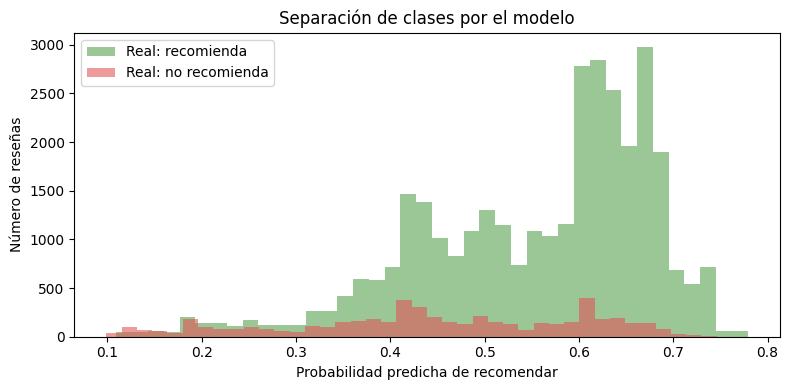

In [ ]:
from pyspark.ml.functions import vector_to_array

# Distribución de la probabilidad de 'recomienda' según la clase real (muestra de 50,000 reseñas)
muestra = (pred_rf.withColumn('prob_recomienda', vector_to_array('probability')[1])
                  .select('label', 'prob_recomienda')
                  .sample(False, 0.01, seed=1).limit(50000).toPandas())

plt.figure(figsize=(8, 4))
plt.hist(muestra[muestra['label'] == 1.0]['prob_recomienda'], bins=40, alpha=0.6, label='Real: recomienda', color='#59a14f')
plt.hist(muestra[muestra['label'] == 0.0]['prob_recomienda'], bins=40, alpha=0.6, label='Real: no recomienda', color='#e15759')
plt.xlabel('Probabilidad predicha de recomendar')
plt.ylabel('Número de reseñas')
plt.title('Separación de clases por el modelo')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación de la separación de clases**

- **Hay mucho traslape.** Las reseñas positivas forman dos bloques (picos alrededor de 0.40–0.45 y 0.60–0.70), mientras que las negativas se reparten casi parejo entre 0.1 y 0.7. No existe una zona donde el modelo discrimine con claridad, lo que concuerda con un AUC-ROC de 0.713.
- **El modelo nunca está seguro:** la probabilidad máxima ronda 0.78 y casi no hay valores arriba de 0.75. Los pesos por clase comprimen las probabilidades hacia el centro.
- **El umbral de 0.5 corta justo el bloque de positivas de 0.40–0.50**, que es el origen de gran parte de los 1,035,947 falsos negativos. Bajar el umbral recuperaría positivas, pero dejaría pasar más negativas; ese compromiso se mide en 7.1 (celda F).
- **Cómo leer la gráfica:** las barras son conteos, así que la clase positiva domina visualmente por el desbalance (≈7 a 1) y no por el modelo. Para comparar las formas de ambas distribuciones convendría normalizarlas (`density=True`).

In [ ]:
# Guardar el modelo para reutilizarlo en la sección de pruebas
MODEL_PATH = '/content/modelo_rf_steam'
model_rf.write().overwrite().save(MODEL_PATH)
print('Modelo guardado en', MODEL_PATH)

Modelo guardado en /content/modelo_rf_steam


## 6. Exportación de datos para el tablero de Tableau

Exportamos tres archivos CSV ligeros:
1. `steam_muestra.csv`: ~77,000 reseñas (76,845 en esta ejecución) con la predicción del modelo.
2. `steam_juegos.csv`: resumen de los 100 juegos con más reseñas (total de reseñas, % de recomendación, horas promedio).
3. `steam_mensual.csv`: resumen mensual de reseñas y % de recomendación.

In [ ]:
# 1) Muestra con predicciones
muestra_tab = (pred_rf
    .withColumn('prob_recomienda', F.round(vector_to_array('probability')[1], 4))
    .select('app_id', 'app_name', 'language', 'review_month', 'recommended',
            F.col('prediction').cast('int').alias('prediccion'), 'prob_recomienda',
            (F.col('playtime_at_review') / 60).alias('horas_al_reseñar'),
            (F.col('playtime_forever') / 60).alias('horas_totales'),
            'num_games_owned', 'num_reviews', 'review_len',
            'steam_purchase', 'received_for_free', 'early_access')
    .sample(False, 0.02, seed=7).limit(150000).toPandas())
muestra_tab['acierto'] = (muestra_tab['recommended'] == muestra_tab['prediccion']).astype(int)
muestra_tab.to_csv('/content/steam_muestra.csv', index=False)

# 2) Resumen por juego (top 100 por número de reseñas)
juegos = (df.groupBy('app_id', 'app_name')
            .agg(F.count('*').alias('total_reseñas'),
                 F.round(100 * F.avg('label'), 2).alias('pct_recomendado'),
                 F.round(F.avg('playtime_at_review') / 60, 1).alias('horas_prom_al_reseñar'),
                 F.round(F.avg('review_len'), 1).alias('long_prom_reseña'),
                 F.round(100 * F.avg('is_english'), 1).alias('pct_ingles'))
            .orderBy(F.desc('total_reseñas')).limit(100).toPandas())
juegos.to_csv('/content/steam_juegos.csv', index=False)

# 3) Resumen mensual
mensual = (df.groupBy('review_month')
             .agg(F.count('*').alias('total_reseñas'),
                  F.round(100 * F.avg('label'), 2).alias('pct_recomendado'))
             .orderBy('review_month').toPandas())
mensual.to_csv('/content/steam_mensual.csv', index=False)

print('Muestra:', len(muestra_tab), 'filas | Juegos:', len(juegos), 'filas | Meses:', len(mensual), 'filas')
muestra_tab.head()

Muestra: 76845 filas | Juegos: 100 filas | Meses: 123 filas


,app_id,app_name,language,review_month,recommended,prediccion,prob_recomienda,horas_al_reseñar,horas_totales,num_games_owned,num_reviews,review_len,steam_purchase,received_for_free,early_access,acierto
0,4000,Garry's Mod,brazilian,2013-11,1,1,0.6091,6.366667,57.083333,129.0,14.0,20,1,0,0,1
1,4000,Garry's Mod,brazilian,2013-12,1,1,0.6099,8.250000,26.933333,78.0,2.0,25,0,0,0,1
2,4000,Garry's Mod,brazilian,2014-01,1,0,0.3920,1.583333,2.983333,115.0,3.0,18,1,0,0,0
3,4000,Garry's Mod,brazilian,2014-05,1,1,0.6031,68.550000,125.616667,183.0,17.0,94,1,0,0,1
4,4000,Garry's Mod,brazilian,2014-05,1,1,0.5058,22.016667,189.550000,63.0,10.0,257,1,0,0,1


In [ ]:
from google.colab import files

files.download('/content/steam_muestra.csv')
files.download('/content/steam_juegos.csv')
files.download('/content/steam_mensual.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Pruebas y predicciones con datos nuevos

Probamos el modelo de dos formas:
- **A) Juegos nuevos:** reseñas de los juegos apartados (holdout) que el modelo nunca vio, ni en entrenamiento ni en la evaluación de la sección 5.
- **B) Reseñas hipotéticas** definidas manualmente, para ver predicciones concretas.

In [ ]:
from pyspark.ml import PipelineModel

# Cargar el modelo guardado
modelo = PipelineModel.load(MODEL_PATH)

# Predicciones sobre juegos que el modelo nunca vio
pred_nuevos = modelo.transform(holdout).cache()

metricas_nuevos = pd.DataFrame([evaluate_clf(pred_nuevos, 'Random Forest - juegos nuevos')])
metricas_nuevos

,modelo,areaUnderROC,areaUnderPR,accuracy,f1,weightedPrecision,weightedRecall
0,Random Forest - juegos nuevos,0.6701,0.9685,0.7215,0.7954,0.9123,0.7215


In [ ]:
# Ejemplos de predicciones reales vs. predichas en juegos nuevos
(pred_nuevos
 .withColumn('prob_recomienda', F.round(vector_to_array('probability')[1], 3))
 .select('app_name',
         F.round(F.col('playtime_at_review') / 60, 1).alias('horas_al_reseñar'),
         'review_len',
         F.col('recommended').alias('real'),
         F.col('prediction').cast('int').alias('predicho'),
         'prob_recomienda')
 .sample(False, 0.00005, seed=3)
 .limit(15)
 .show(truncate=40))

+--------------------------+----------------+----------+----+--------+---------------+
|                  app_name|horas_al_reseñar|review_len|real|predicho|prob_recomienda|
+--------------------------+----------------+----------+----+--------+---------------+
|               Trailmakers|             4.6|        10|   1|       0|          0.376|
|               Trailmakers|             3.8|        13|   0|       1|           0.67|
|Freeman: Guerrilla Warfare|             2.0|       290|   1|       0|          0.453|
|            Planet Coaster|           138.6|        87|   1|       1|          0.544|
|                  Among Us|             3.5|        30|   1|       0|          0.385|
|                  Among Us|             4.5|       237|   1|       0|          0.464|
|                  Among Us|            28.5|        31|   1|       1|          0.675|
|      DRAGON BALL FighterZ|             5.2|        10|   1|       1|          0.673|
|          Cities: Skylines|           977.

**Interpretación de los ejemplos en juegos nuevos**

- El modelo acertó **7 de 15** (47%). Es una muestra muy pequeña, pero muestra un patrón: los errores se concentran en los extremos de horas jugadas. Reseñas con muy pocas horas (3.5 a 4.6 h en Among Us y Trailmakers) y con muchísimas (977 h y 1,340 h en Cities: Skylines) se predijeron como "no recomienda" aunque eran positivas; los aciertos están, en su mayoría, entre 4 y 180 horas.
- Las reseñas de Cities: Skylines con 977 h y 1,340 h reciben probabilidades de 0.376 y 0.364, a pesar de que sus autores recomiendan el juego. Es consistente con el coeficiente negativo de `log_playtime_review`: el modelo asocia "muchas horas al reseñar" con reseñas críticas, lo que penaliza a los jugadores muy fieles.
- 14 de las 15 reseñas son positivas, como era de esperar con una tasa base cercana a 87%. La celda G de 7.1 verifica este patrón con todos los datos y no con una muestra de 15.
- **Confirmado con todos los datos:** la celda G de 7.1 muestra que la exactitud cae a 46.0% con menos de 2 horas y a 48.3% con más de 200 horas, contra 77.6% entre 10 y 50 horas.


In [ ]:
# B) Reseñas hipotéticas
# Columnas: minutos jugados al reseñar, minutos totales, juegos que posee, reseñas que ha escrito,
#           longitud de la reseña (caracteres), compra en Steam, juego gratis, acceso anticipado, idioma
datos_nuevos = [
    (15.0,    15.0,    8.0,    1.0,   25, 1, 0, 0, 'english'),      # jugó 15 min, reseña muy corta
    (120.0,   300.0,   40.0,   5.0,   180, 1, 0, 0, 'english'),     # jugador casual
    (6000.0,  9000.0,  250.0,  60.0,  900, 1, 0, 0, 'english'),     # 100 horas, reseña larga
    (30000.0, 45000.0, 1200.0, 400.0, 1500, 1, 0, 0, 'english'),    # 500 horas, coleccionista veterano
    (45.0,    45.0,    3.0,    1.0,   60, 0, 1, 1, 'spanish'),      # recibió el juego gratis, acceso anticipado
    (600.0,   650.0,   90.0,   20.0,  350, 1, 0, 1, 'russian'),     # 10 horas, acceso anticipado
]

esquema = ('playtime_at_review double, playtime_forever double, num_games_owned double, num_reviews double, '
           'review_len int, steam_purchase int, received_for_free int, early_access int, language string')
nuevos_df = add_features(spark.createDataFrame(datos_nuevos, schema=esquema))

(modelo.transform(nuevos_df)
       .withColumn('prob_recomienda', F.round(vector_to_array('probability')[1], 3))
       .select(F.round(F.col('playtime_at_review') / 60, 1).alias('horas_al_reseñar'),
               'num_games_owned', 'review_len', 'language',
               F.when(F.col('prediction') == 1.0, 'Recomienda').otherwise('No recomienda').alias('prediccion'),
               'prob_recomienda')
       .show(truncate=False))

+----------------+---------------+----------+--------+-------------+---------------+
|horas_al_reseñar|num_games_owned|review_len|language|prediccion   |prob_recomienda|
+----------------+---------------+----------+--------+-------------+---------------+
|0.3             |8.0            |25        |english |No recomienda|0.198          |
|2.0             |40.0           |180       |english |No recomienda|0.472          |
|100.0           |250.0          |900       |english |No recomienda|0.411          |
|500.0           |1200.0         |1500      |english |No recomienda|0.358          |
|0.8             |3.0            |60        |spanish |No recomienda|0.288          |
|10.0            |90.0           |350       |russian |No recomienda|0.446          |
+----------------+---------------+----------+--------+-------------+---------------+



**Interpretación (B): recomendación según horas jugadas al reseñar**

- **La relación tiene forma de campana, no es lineal.** Recomienda 70.7% con menos de 2 horas, 89.7% entre 2 y 10 horas, 91.1% entre 10 y 50 horas (el máximo), 88.8% entre 50 y 200 horas y 81.6% con más de 200 horas. El promedio general es 87.5%.
- **Las primeras 2 horas son decisivas:** casi 3 de cada 10 reseñas hechas tan pronto (29.3%) son negativas. Una posible explicación es que coincide con la ventana de reembolso de Steam (menos de 2 horas de juego): quien se decepciona rápido reseña y pide su dinero. Es una hipótesis que los datos no prueban.
- **Con más de 200 horas la satisfacción baja ≈9 puntos** respecto al máximo. Puede reflejar desgaste de jugadores veteranos o un efecto de composición, ya que los juegos con muchas horas por jugador (como PUBG, ver D) tienden a recomendarse menos.
- **Por qué importa:** el 33.6% de las reseñas está en el rango 10 a 50 horas, donde el modelo funciona mejor, y los extremos son justo donde falla (ver G).

**Interpretación de las pruebas:**

- **Juegos nuevos:** en juegos que el modelo nunca vio, el AUC-ROC bajó de 0.713 (conjunto de prueba) a 0.670, una pérdida moderada de capacidad para separar las clases. El AUC-PR (0.969), el accuracy (0.722) y el F1 ponderado (0.795) salieron más altos que en la prueba, probablemente porque estas métricas dependen de la proporción de reseñas positivas de cada conjunto. El AUC-ROC no depende de esa proporción, por eso es la métrica más confiable para comparar. En conjunto, el modelo generaliza a juegos nuevos con un desempeño modesto.
- **Reseñas hipotéticas:** las seis fueron clasificadas como "No recomienda", con probabilidades entre 0.198 y 0.472. Esto no es coherente con lo esperado (por ejemplo, un jugador con 500 horas y 1,200 juegos debería inclinarse a recomendar). Dos razones: (1) las reseñas largas (900 a 1,500 caracteres) empujan la predicción hacia "no recomienda", porque en los datos las reseñas negativas son más largas (267 caracteres en promedio contra 156 de las positivas); (2) al entrenar con pesos por clase, el modelo se vuelve más propenso a predecir la clase negativa, y las probabilidades quedan concentradas entre 0.35 y 0.68, cerca del umbral de 0.5.

## 7.1 Análisis adicional: ¿dónde acierta y dónde falla el modelo?

Las siguientes celdas profundizan en lo observado arriba. Usan los objetos que ya existen en la sesión (`df`, `pred_rf`, `mensual`), así que deben ejecutarse **antes** de `spark.stop()`.

In [ ]:
# A) Estadísticos robustos: medianas (no se ven afectadas por los valores absurdos)
(df.groupBy('label')
   .agg(F.round(F.expr('percentile_approx(playtime_at_review, 0.5)') / 60, 1).alias('mediana_horas_al_reseñar'),
        F.round(F.expr('percentile_approx(playtime_forever, 0.5)') / 60, 1).alias('mediana_horas_totales'),
        F.expr('percentile_approx(num_games_owned, 0.5)').alias('mediana_juegos'),
        F.expr('percentile_approx(num_reviews, 0.5)').alias('mediana_reseñas_escritas'),
        F.expr('percentile_approx(review_len, 0.5)').alias('mediana_long_reseña'))
   .orderBy('label')
   .show())

# Cuántos registros tienen valores poco creíbles (criterio: umbrales generosos)
print('num_games_owned > 50,000 :', df.filter(F.col('num_games_owned') > 50000).count())
print('num_reviews > 50,000     :', df.filter(F.col('num_reviews') > 50000).count())
print('review_len > 50,000      :', df.filter(F.col('review_len') > 50000).count())
print('horas al reseñar > 50,000:', df.filter(F.col('playtime_at_review') > 50000 * 60).count())

+-----+------------------------+---------------------+--------------+------------------------+-------------------+
|label|mediana_horas_al_reseñar|mediana_horas_totales|mediana_juegos|mediana_reseñas_escritas|mediana_long_reseña|
+-----+------------------------+---------------------+--------------+------------------------+-------------------+
|  0.0|                    37.2|                 78.9|          63.0|                     4.0|                 63|
|  1.0|                    30.9|                 71.3|          60.0|                     4.0|                 37|
+-----+------------------------+---------------------+--------------+------------------------+-------------------+

num_games_owned > 50,000 : 5
num_reviews > 50,000     : 2
review_len > 50,000      : 55
horas al reseñar > 50,000: 2


**Interpretación (A): medianas y valores atípicos**

- **Las medianas cuentan una historia más sobria que los promedios.** Los que no recomiendan acumulan 37.2 h al reseñar contra 30.9 h de quienes recomiendan (+20%) y 78.9 h contra 71.3 h en total (+11%). La diferencia existe, pero es moderada.
- **La longitud es la diferencia más clara:** mediana de 63 caracteres en reseñas negativas contra 37 en positivas (+70%).
- **Tamaño de biblioteca y reseñas escritas no separan a los grupos por sí solos** (63 contra 60 juegos; 4 contra 4 reseñas).
- **Los valores absurdos son muy pocos:** 5 registros con más de 50,000 juegos, 2 con más de 50,000 reseñas escritas, 55 con reseñas de más de 50,000 caracteres y 2 con más de 50,000 horas, de 21.7 millones. Esto respalda la decisión de no filtrarlos: casi no afectan al modelo (que usa `log1p` y árboles), y el problema se resuelve en el análisis descriptivo usando medianas.

   rango_horas  reseñas  pct_recomienda
0     1) < 2 h  1289926            70.7
1    2) 2-10 h  4411423            89.7
2   3) 10-50 h  7303312            91.1
3  4) 50-200 h  5083478            88.8
4   5) > 200 h  3633548            81.6


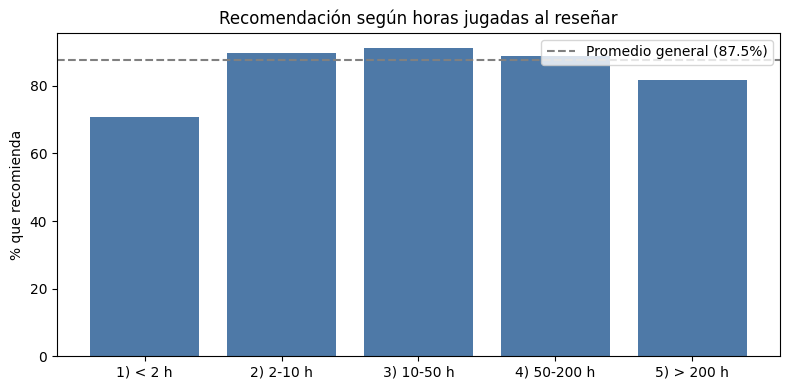

In [ ]:
# B) Porcentaje de recomendación según horas jugadas al reseñar
rango = (F.when(F.col('playtime_at_review') < 120, '1) < 2 h')
          .when(F.col('playtime_at_review') < 600, '2) 2-10 h')
          .when(F.col('playtime_at_review') < 3000, '3) 10-50 h')
          .when(F.col('playtime_at_review') < 12000, '4) 50-200 h')
          .otherwise('5) > 200 h'))

por_horas = (df.withColumn('rango_horas', rango)
               .groupBy('rango_horas')
               .agg(F.count('*').alias('reseñas'), F.round(100 * F.avg('label'), 1).alias('pct_recomienda'))
               .orderBy('rango_horas').toPandas())
print(por_horas)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_horas['rango_horas'], por_horas['pct_recomienda'], color='#4e79a7')
ax.axhline(87.5, color='gray', linestyle='--', label='Promedio general (87.5%)')
ax.set_ylabel('% que recomienda'); ax.set_title('Recomendación según horas jugadas al reseñar')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretación (B): recomendación según horas jugadas al reseñar**

- **La relación tiene forma de campana, no es lineal.** Recomienda 70.7% con menos de 2 horas, 89.7% entre 2 y 10 horas, 91.1% entre 10 y 50 horas (el máximo), 88.8% entre 50 y 200 horas y 81.6% con más de 200 horas. El promedio general es 87.5%.
- **Las primeras 2 horas son decisivas:** casi 3 de cada 10 reseñas hechas tan pronto (29.3%) son negativas. Una posible explicación es que coincide con la ventana de reembolso de Steam (menos de 2 horas de juego): quien se decepciona rápido reseña y pide su dinero. Es una hipótesis que los datos no prueban.
- **Con más de 200 horas la satisfacción baja ≈9 puntos** respecto al máximo. Puede reflejar desgaste de jugadores veteranos o un efecto de composición, ya que los juegos con muchas horas por jugador (como PUBG, ver D) tienden a recomendarse menos.
- **Por qué importa:** el 33.6% de las reseñas está en el rango 10 a 50 horas, donde el modelo funciona mejor, y los extremos son justo donde falla (ver G).

    language  reseñas  pct_recomienda
0    english  9623588            89.1
1   schinese  3760852            77.1
2    russian  2345647            89.2
3  brazilian   836585            94.4
4    spanish   812313            92.8
5     german   751841            88.5
6    turkish   635171            90.3
7    koreana   613197            84.2
8     french   541118            90.5
9     polish   495092            94.6


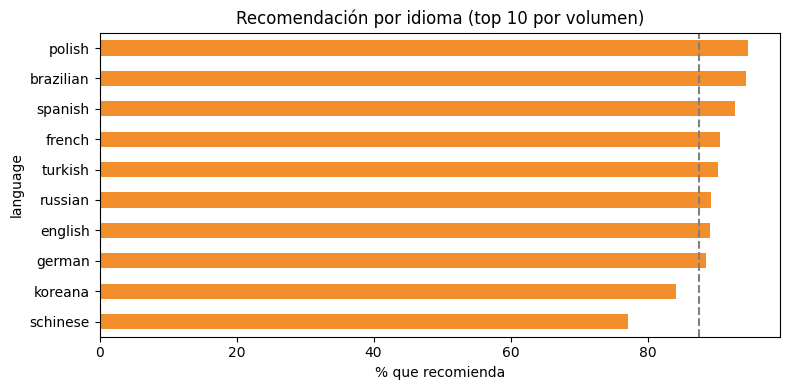

In [ ]:
# C) Recomendación por idioma (los 10 idiomas con más reseñas)
por_idioma = (df.groupBy('language')
                .agg(F.count('*').alias('reseñas'), F.round(100 * F.avg('label'), 1).alias('pct_recomienda'))
                .orderBy(F.desc('reseñas')).limit(10).toPandas())
print(por_idioma)

por_idioma.sort_values('pct_recomienda').plot.barh(x='language', y='pct_recomienda', legend=False,
                                                   color='#f28e2b', figsize=(8, 4))
plt.axvline(87.5, color='gray', linestyle='--')
plt.xlabel('% que recomienda'); plt.title('Recomendación por idioma (top 10 por volumen)')
plt.tight_layout(); plt.show()

**Interpretación (C): recomendación por idioma**

- **El chino simplificado es el caso atípico:** recomienda 77.1% con 3.76 millones de reseñas (17.3% del total), por debajo del promedio de 87.5%. El coreano (84.2%) también queda abajo.
- **Inglés (89.1%) y ruso (89.2%) están cerca del promedio**, mientras que portugués brasileño (94.4%), polaco (94.6%) y español (92.8%) están por encima.
- **Hipótesis (por verificar):** como los jugadores en chino se concentran en algunos juegos populares y con crítica mixta, es posible que el efecto sea de composición por juego (por ejemplo, PUBG) y no del idioma en sí. Un cruce idioma por juego lo confirmaría.
- **Consecuencia para el modelo:** `is_english` agrupa en un solo bloque idiomas con comportamientos muy distintos. Usar el idioma como variable categórica (al menos chino simplificado aparte) sería una mejora natural.

In [ ]:
# D) Juegos mejor y peor valorados (mínimo 50,000 reseñas para evitar ruido)
por_juego = (df.groupBy('app_name')
               .agg(F.count('*').alias('reseñas'), F.round(100 * F.avg('label'), 1).alias('pct_recomienda'))
               .filter(F.col('reseñas') >= 50000)
               .toPandas())
print('Juegos con >= 50,000 reseñas:', len(por_juego))
print('\nMejor valorados:'); print(por_juego.sort_values('pct_recomienda', ascending=False).head(8).to_string(index=False))
print('\nPeor valorados:');  print(por_juego.sort_values('pct_recomienda').head(8).to_string(index=False))

Juegos con >= 50,000 reseñas: 104

Mejor valorados:
                     app_name  reseñas  pct_recomienda
                     Factorio   108225            98.9
                        Hades   118416            98.9
                     Portal 2   231291            98.8
              Half-Life: Alyx    51099            98.7
                     RimWorld    93956            98.3
             Wallpaper Engine   291583            98.2
                    Helltaker    86306            98.1
The Binding of Isaac: Rebirth   124295            98.1

Peor valorados:
                           app_name  reseñas  pct_recomienda
      PLAYERUNKNOWN'S BATTLEGROUNDS  1643640            53.9
                          For Honor    93748            65.7
                       No Man's Sky   181908            69.0
Tom Clancy's Ghost Recon® Wildlands    51438            77.0
                          Far Cry 5    85713            77.6
                       Conan Exiles    62126            77.8
         

**Interpretación (D): juegos mejor y peor valorados** (104 juegos con al menos 50,000 reseñas)

- **Mejor valorados (≥98%):** Factorio y Hades (98.9%), Portal 2 (98.8%), Half-Life: Alyx (98.7%) y RimWorld (98.3%). Son en su mayoría juegos de un solo jugador, de gestión o con diseño muy pulido.
- **Peor valorados:** PUBG (53.9%), For Honor (65.7%), No Man's Sky (69.0%), Ghost Recon Wildlands (77.0%) y Far Cry 5 (77.6%), seguidos de Conan Exiles, Fallout 4 y ARK. Predominan los juegos en línea, de mundo abierto o de supervivencia.
- **PUBG pesa de manera desproporcionada.** Es el juego con más reseñas (1,643,640, el 7.6% del total) y el que menos se recomienda; con ≈46% de reseñas negativas aporta ≈757,000 reseñas negativas, es decir, **≈28% de todas las negativas del conjunto** (2,720,231). La clase "no recomienda" está dominada por un solo título.
- **Implicación para el modelo:** el juego en sí es una señal fuerte que el modelo no ve (no usa identificador, género ni precio), lo que ayuda a explicar su desempeño moderado y la caída del AUC-ROC de 0.713 a 0.670 en juegos nuevos.

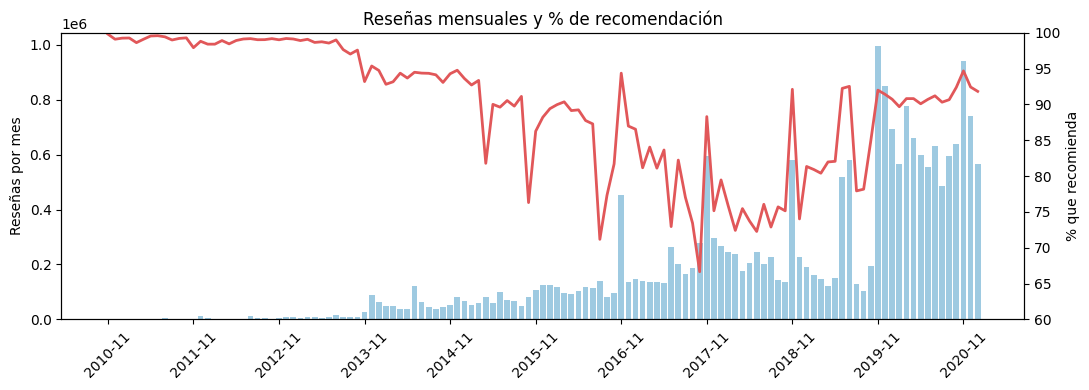

Mes con más reseñas:
review_month  total_reseñas  pct_recomendado
     2019-11         993108            92.00
     2020-11         941891            94.69
     2019-12         848258            91.42

Meses con menor % de recomendación (con >= 10,000 reseñas):
review_month  total_reseñas  pct_recomendado
     2017-10         277458            66.66
     2016-08         141454            71.18
     2018-06         245757            72.28
     2018-03         239905            72.43
     2018-08         225501            72.90


In [ ]:
# E) Evolución mensual: volumen de reseñas y % de recomendación (usa el DataFrame 'mensual' de la sección 6)
m = mensual.copy()
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(range(len(m)), m['total_reseñas'], color='#9ecae1')
ax1.set_ylabel('Reseñas por mes')
ax1.set_xticks(range(0, len(m), 12)); ax1.set_xticklabels(m['review_month'].iloc[::12], rotation=45)
ax2 = ax1.twinx()
ax2.plot(range(len(m)), m['pct_recomendado'], color='#e15759', linewidth=2)
ax2.set_ylabel('% que recomienda'); ax2.set_ylim(60, 100)
plt.title('Reseñas mensuales y % de recomendación'); plt.tight_layout(); plt.show()

print('Mes con más reseñas:'); print(m.sort_values('total_reseñas', ascending=False).head(3).to_string(index=False))
print('\nMeses con menor % de recomendación (con >= 10,000 reseñas):')
print(m[m['total_reseñas'] >= 10000].sort_values('pct_recomendado').head(5).to_string(index=False))

**Interpretación (E): evolución mensual**

- **Volumen:** crece de menos de 100,000 reseñas al mes en 2014 y 2015 a máximos de 993,108 en noviembre de 2019, 941,891 en noviembre de 2020 y 848,258 en diciembre de 2019. Los picos caen en noviembre y diciembre, lo que podría deberse a las temporadas de rebajas de Steam (hipótesis).
- **Satisfacción:** ronda 92 a 95% en 2014 y 2015, se vuelve más baja y volátil entre 2016 y 2018 (mínimos de 66.7% en octubre de 2017, 71.2% en agosto de 2016 y 72.3% en junio de 2018) y desde finales de 2019 se estabiliza cerca de 90 a 92%.
- **Cuidado al interpretarlo:** el porcentaje mensual mezcla juegos distintos, así que un mes bajo puede deberse a uno o dos lanzamientos muy reseñados y no a un cambio en toda la plataforma. Como hipótesis, agosto de 2016 coincide con el lanzamiento de No Man's Sky (69.0% en total) y octubre de 2017 con el auge de PUBG; ambas requieren verificarse cruzando juego y mes.

In [ ]:
# F) Efecto del umbral de decisión sobre la clase "No recomienda" (conjunto de prueba, Random Forest)
pp = pred_rf.withColumn('p1', vector_to_array('probability')[1]).select('label', 'p1').cache()
n_neg = pp.filter('label = 0').count()

filas = []
for t in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    r = pp.agg(
        F.sum(F.when((F.col('p1') < t) & (F.col('label') == 0), 1).otherwise(0)).alias('tn'),
        F.sum(F.when((F.col('p1') < t) & (F.col('label') == 1), 1).otherwise(0)).alias('fn'),
        F.sum(F.when((F.col('p1') >= t) & (F.col('label') == 1), 1).otherwise(0)).alias('tp')).first()
    prec_neg = r['tn'] / max(r['tn'] + r['fn'], 1)
    rec_neg = r['tn'] / n_neg
    f1_neg = 2 * prec_neg * rec_neg / max(prec_neg + rec_neg, 1e-9)
    filas.append({'umbral': t, 'precision_neg': round(prec_neg, 3), 'recall_neg': round(rec_neg, 3),
                  'f1_neg': round(f1_neg, 3), 'positivas_mal_marcadas': r['fn']})
umbrales = pd.DataFrame(filas)
print(umbrales.to_string(index=False))

 umbral  precision_neg  recall_neg  f1_neg  positivas_mal_marcadas
   0.40          0.335       0.351   0.343                  359074
   0.45          0.266       0.516   0.351                  737260
   0.50          0.235       0.617   0.340                 1035947
   0.55          0.214       0.693   0.327                 1315171
   0.60          0.194       0.775   0.310                 1662396
   0.65          0.160       0.923   0.273                 2494562


**Interpretación (F): efecto del umbral de decisión** (clase "No recomienda", conjunto de prueba)

| Umbral | Precisión | Recall | F1 | Positivas mal marcadas |
|---|---|---|---|---|
| 0.40 | 0.335 | 0.351 | 0.343 | 359,074 |
| 0.45 | 0.266 | 0.516 | 0.351 | 737,260 |
| 0.50 | 0.235 | 0.617 | 0.340 | 1,035,947 |
| 0.60 | 0.194 | 0.775 | 0.310 | 1,662,396 |
| 0.65 | 0.160 | 0.923 | 0.273 | 2,494,562 |

- **El umbral solo mueve el compromiso entre precisión y recall; no mejora el modelo.** El F1 apenas varía (0.27 a 0.35), consistente con un AUC-ROC de 0.713.
- **Umbral 0.40 para alertas precisas:** la precisión sube a 0.335 (≈2.5× la tasa base de 13.4%) y las positivas mal marcadas bajan de 1,035,947 a 359,074 (−65%), a cambio de detectar solo 35.1% de las negativas.
- **Umbral 0.45 para un balance:** maximiza el F1 (0.351), con un recall de 51.6%.
- **Umbrales altos (0.60 a 0.65) para no dejar escapar negativas:** el recall llega a 77.5% y 92.3%, pero con 0.65 se marca erróneamente al 75% de las positivas (2,494,562 de 3,328,310), lo que volvería inmanejable la revisión.
- **0.5 es un punto intermedio sin una justificación particular.** La elección depende del costo de revisar una reseña frente al costo de pasar por alto una negativa.

In [ ]:
# G) ¿Dónde falla el modelo? Desempeño por rango de horas (conjunto de prueba, Random Forest)
(pred_rf.withColumn('rango_horas', rango)
        .groupBy('rango_horas')
        .agg(F.count('*').alias('reseñas'),
             F.round(100 * F.avg((F.col('label') == F.col('prediction')).cast('int')), 1).alias('accuracy_pct'),
             F.round(100 * F.avg('label'), 1).alias('pct_real_recomienda'),
             F.round(100 * F.avg('prediction'), 1).alias('pct_predicho_recomienda'))
        .orderBy('rango_horas')
        .show())

+-----------+-------+------------+-------------------+-----------------------+
|rango_horas|reseñas|accuracy_pct|pct_real_recomienda|pct_predicho_recomienda|
+-----------+-------+------------+-------------------+-----------------------+
|   1) < 2 h| 221362|        46.0|               68.2|                   18.3|
|  2) 2-10 h| 761901|        74.7|               89.1|                   75.0|
| 3) 10-50 h|1274523|        77.6|               90.5|                   80.1|
|4) 50-200 h| 897471|        68.9|               87.8|                   68.4|
| 5) > 200 h| 689367|        48.3|               80.8|                   35.2|
+-----------+-------+------------+-------------------+-----------------------+



**Interpretación (G): dónde falla el modelo**

| Horas al reseñar | Reseñas | Exactitud | % real que recomienda | % predicho que recomienda |
|---|---|---|---|---|
| < 2 h | 221,362 | 46.0% | 68.2% | 18.3% |
| 2 a 10 h | 761,901 | 74.7% | 89.1% | 75.0% |
| 10 a 50 h | 1,274,523 | 77.6% | 90.5% | 80.1% |
| 50 a 200 h | 897,471 | 68.9% | 87.8% | 68.4% |
| > 200 h | 689,367 | 48.3% | 80.8% | 35.2% |

- **El modelo funciona de manera moderada en el centro y falla en los extremos.** Entre 2 y 200 horas (76% de la prueba) la exactitud va de 69% a 78%; con menos de 2 horas y con más de 200 baja a 46.0% y 48.3%.
- **El error es sistemático: castiga los extremos.** Con menos de 2 horas, 68.2% de las reseñas son positivas pero el modelo solo predice 18.3% como tales. Con más de 200 horas, 80.8% son positivas y predice 35.2%. En ambos extremos, un modelo que siempre dijera "recomienda" acertaría más (68.2% y 80.8%) que el modelo actual.
- **Causa probable:** las horas entran al modelo de forma monótona (en la regresión logística, con signo negativo para las horas al reseñar) y no capturan la forma de campana que se vio en (B).
- **Mejora sugerida:** variables de rango de horas o un modelo con interacciones.

In [ ]:
# H) Hipótesis: horas jugadas DESPUÉS de reseñar (playtime_forever - playtime_at_review)
despues = df.withColumn('horas_despues', F.greatest(F.col('playtime_forever') - F.col('playtime_at_review'), F.lit(0.0)) / 60)
(despues.groupBy('label')
        .agg(F.round(F.expr('percentile_approx(horas_despues, 0.5)'), 1).alias('mediana_horas_despues'),
             F.round(100 * F.avg((F.col('horas_despues') == 0).cast('int')), 1).alias('pct_no_jugo_despues'))
        .orderBy('label')
        .show())

+-----+---------------------+-------------------+
|label|mediana_horas_despues|pct_no_jugo_despues|
+-----+---------------------+-------------------+
|  0.0|                 13.1|               21.2|
|  1.0|                 20.7|                9.8|
+-----+---------------------+-------------------+



**Interpretación (H): horas jugadas después de reseñar**

- **La hipótesis se sostiene:** los jugadores que no recomiendan juegan una mediana de 13.1 horas después de reseñar, contra 20.7 horas de quienes recomiendan (+58%).
- **Uno de cada cinco críticos dejó de jugar al reseñar:** 21.2% de las reseñas negativas no tiene horas posteriores, contra 9.8% de las positivas (2.2 veces más).
- **Precauciones:** es una comparación descriptiva. `playtime_forever` se midió en la fecha de extracción de los datos, por lo que las reseñas más recientes han tenido menos tiempo de acumular horas, y eso puede sesgar la comparación.
- **Aplicación:** crear `playtime_after_review` es la mejora más prometedora de ingeniería de variables. Como la variable usa información posterior a la reseña, serviría para analizar reseñas ya escritas, no para predecir antes de que el jugador reseñe (ver limitaciones en 8.9).

In [ ]:
spark.stop()

---
# 8. Reporte final: documentación del proceso

## 8.1 Resumen

En este proyecto se construyó un modelo de **clasificación binaria con PySpark MLlib** para predecir si una reseña de Steam **recomienda o no** un videojuego, usando una base de datos de gran volumen (21,747,371 reseñas, en un CSV de 8.17 GB). El modelo se evaluó con herramientas de PySpark, se probó con juegos que no participaron en el entrenamiento y se acompañó de un tablero de visualización en Tableau. El mejor modelo (Random Forest) alcanzó un AUC-ROC de 0.713 en la prueba y 0.670 en juegos nuevos, lo que indica un desempeño modesto: el perfil del jugador y la longitud de la reseña explican solo una parte de la decisión de recomendar.

## 8.2 Configuración del entorno

- Se trabajó en **Google Colab** (2 núcleos disponibles).
- Se instaló **Java 17** y **PySpark 3.5.1**.
- Se creó una `SparkSession` en modo local (`local[*]`) con 5 GB de memoria para el driver.

## 8.3 Selección de la base de datos

- **Fuente:** Steam Reviews Dataset 2021 (Kaggle, licencia GPL-2.0), descargado con la API de Kaggle (zip de 2.97 GB).
- **Volumen:** 21,747,371 registros, 23 columnas originales y un CSV de 8.17 GB.
- **Justificación:** es un conjunto real y de gran volumen, con variables numéricas, binarias y de texto, y con un tema atractivo (videojuegos). Su tamaño justifica el uso de procesamiento distribuido con Spark.

## 8.4 Preparación de los datos

1. **Conversión a Parquet:** como las reseñas contienen texto con saltos de línea, el CSV es lento de leer directamente con Spark. Se leyó por bloques de 250,000 filas con pandas, se conservaron 14 columnas, se calculó la longitud de cada reseña y se guardó en Parquet (formato columnar), que pasó de 8.17 GB a 352 MB. Se conservaron los 21,747,371 registros.
2. **Limpieza:** se eliminaron nulos y valores inválidos. Se descartaron 25,684 registros (0.1%) y quedaron 21,721,687.
3. **Ingeniería de variables:** se aplicó `log1p` a las variables de conteo por su fuerte sesgo, se creó `is_english` y la variable objetivo `label`.
4. **Exploración:**
   - **Balance de clases:** 87.48% de reseñas positivas (19,001,456) y 12.52% negativas (2,720,231).
   - **Juegos con más reseñas:** PLAYERUNKNOWN'S BATTLEGROUNDS (más de 1.6 millones), Grand Theft Auto V y Tom Clancy's Rainbow Six Siege.
   - **Diferencias entre grupos:** quienes no recomiendan tienen más horas de juego al reseñar (202.3 h contra 138.9 h), más horas totales (331.0 h contra 259.4 h) y escriben reseñas más largas (267.1 contra 156.4 caracteres). Entre quienes escriben en inglés, el 45.1% recomienda y el 38.6% no.

## 8.5 Modelado con MLlib

- **Tipo de problema:** clasificación binaria.
- **Variable objetivo:** `recommended` (1 = recomienda, 0 = no).
- **Variables predictoras:** horas jugadas al reseñar y totales, número de juegos que posee el jugador, número de reseñas que ha escrito, longitud de la reseña, compra en Steam, juego recibido gratis, acceso anticipado e idioma inglés. Se excluyeron los votos de utilidad porque se generan después de publicar la reseña.
- **Partición:** se apartó aproximadamente el 10% de los juegos como conjunto totalmente nuevo (holdout, 2,505,860 reseñas) y el resto se dividió en 80% entrenamiento y 20% prueba (3,844,624 reseñas, semilla 42). El entrenamiento usó el 15% del conjunto de entrenamiento (2,307,184 registros) para reducir el tiempo de cómputo.
- **Desbalance de clases:** se usaron pesos por clase (`weightCol`): 0.578 para la clase positiva y 3.719 para la negativa.
- **Pipeline:** `VectorAssembler` (y `StandardScaler` para la regresión logística) seguido del modelo.
- **Modelos entrenados:** Regresión Logística (modelo base) y Random Forest Classifier (50 árboles, profundidad máxima 8).

## 8.6 Evaluación

Se utilizaron `BinaryClassificationEvaluator` y `MulticlassClassificationEvaluator` sobre el conjunto de prueba:

| Modelo | AUC-ROC | AUC-PR | Accuracy | F1 ponderado |
|---|---|---|---|---|
| Regresión Logística | 0.6410 | 0.9137 | 0.6042 | 0.6671 |
| Random Forest | 0.7128 | 0.9339 | 0.6791 | 0.7278 |

- El modelo con mejor desempeño fue **Random Forest**, superior en las cuatro métricas.
- **Matriz de confusión del Random Forest:** 318,369 verdaderos negativos, 197,945 falsos positivos, 1,035,947 falsos negativos y 2,292,363 verdaderos positivos. El recall es de **0.689** para la clase positiva (recomienda) y de **0.617** para la negativa (no recomienda). La precisión de la clase negativa es de solo 0.235, es decir, muchas de las reseñas que el modelo marca como "no recomienda" en realidad sí recomiendan.
- **Cómo leer las métricas:** el accuracy (67.9%) es menor que el de un modelo trivial que siempre dijera "recomienda" (aproximadamente 87%), porque los pesos por clase sacrifican accuracy a cambio de detectar mejor las reseñas negativas. El AUC-PR alto (0.934) debe interpretarse con cuidado, porque la clase positiva es mayoritaria y el AUC-PR de un modelo sin capacidad predictiva sería cercano a 0.87. Por eso el AUC-ROC (0.713) es la métrica más informativa: indica una capacidad moderada para separar las clases.
- **Variables más importantes (Random Forest):** horas totales jugadas (~0.25), longitud de la reseña (~0.25) y horas al reseñar (~0.22), seguidas de idioma inglés (~0.11) y juegos que posee el jugador (~0.09). Haber comprado el juego en Steam o recibirlo gratis prácticamente no influye.
- **Interpretación:** en la regresión logística, más horas totales jugadas aumentan la probabilidad de recomendar (coeficiente +0.44), mientras que las reseñas más largas la reducen (-0.43): quien está inconforme tiende a explayarse más. Esto coincide con lo observado en la exploración.

## 8.6.1 Observaciones analíticas

1. **Los datos tienen errores de origen que afectan a muy pocos registros.** `num_games_owned` y `num_reviews` llegan a ≈4.4 × 10¹² (cerca de 2⁴²), pero solo 5 y 2 registros superan los 50,000 y 55 reseñas pasan de 50,000 caracteres, de 21.7 millones. No se filtraron: `log1p` y los árboles limitan su efecto, y el análisis descriptivo usa medianas.
2. **Quien no recomienda juega algo más y escribe mucho más.** Con medianas: 37.2 h contra 30.9 h al reseñar (+20%) y reseñas de 63 contra 37 caracteres (+70%). Los promedios exageraban la diferencia de horas (+46%).
3. **La relación con las horas jugadas tiene forma de campana.** Recomienda 70.7% con menos de 2 horas, 91.1% entre 10 y 50 horas y 81.6% con más de 200 horas.
4. **Un solo juego domina las reseñas negativas.** PUBG tiene el 7.6% de las reseñas, la menor recomendación (53.9%) y ≈28% de todas las reseñas negativas. Los juegos mejor valorados (Factorio, Hades, Portal 2) superan 98%.
5. **El chino simplificado baja el promedio general** (77.1% con el 17.3% de las reseñas, contra 89.1% del inglés). Probablemente sea un efecto de composición por juego, que debería verificarse.
6. **La satisfacción mensual fue más baja y volátil entre 2016 y 2018** (mínimo de 66.7% en octubre de 2017) y desde finales de 2019 se estabiliza alrededor de 90%.
7. **El modelo es una señal moderada, no un clasificador confiable.** De las reseñas que marca como negativas, solo 23.5% lo son (lift de ≈1.75× sobre una tasa base de 13.4%). Mover el umbral solo cambia el compromiso entre precisión y recall: con 0.40 la precisión sube a 0.335 (≈2.5×) y con 0.45 se maximiza el F1 (0.351).
8. **El modelo falla en los extremos de horas:** exactitud de 46.0% con menos de 2 horas y de 48.3% con más de 200, contra 77.6% entre 10 y 50 horas.
9. **Las horas jugadas después de reseñar separan a los grupos.** Mediana de 13.1 h en reseñas negativas contra 20.7 h en positivas, y 21.2% contra 9.8% de reseñas sin juego posterior. Crear `playtime_after_review` es la mejora más prometedora.

## 8.7 Pruebas con datos nuevos

- **Juegos nuevos (holdout):** AUC-ROC = 0.6701, AUC-PR = 0.9685, F1 = 0.7954, Accuracy = 0.7215. El AUC-ROC es inferior al de la prueba original (0.7128), lo que indica una pérdida moderada de capacidad de discriminación en juegos que el modelo no vio. Las otras métricas salieron más altas, probablemente porque dependen de la proporción de reseñas positivas de cada conjunto. En general, el modelo generaliza a juegos nuevos, aunque con un desempeño modesto.
- **Ejemplos reales en juegos nuevos:** en una muestra de 15 reseñas (Cities: Skylines, Among Us, Trailmakers, entre otros) acertó en 7. Es una muestra pequeña, pero ilustra que el modelo se equivoca con frecuencia, sobre todo al marcar como negativas reseñas que sí recomiendan.
- **Reseñas hipotéticas:** las predicciones fueron **poco coherentes** con lo esperado: las seis reseñas se clasificaron como "No recomienda", con probabilidades entre 0.198 y 0.472. Por ejemplo, un jugador con 500 horas, 1,200 juegos y una reseña de 1,500 caracteres obtuvo 0.358, cuando se esperaría una probabilidad alta de recomendar. Esto se explica porque las reseñas largas empujan la predicción hacia la clase negativa y porque el entrenamiento con pesos por clase concentra las probabilidades cerca del umbral de 0.5.

## 8.8 Visualización en Tableau

Se exportaron tres archivos (`steam_muestra.csv` con 76,845 reseñas y sus predicciones, `steam_juegos.csv` con los 100 juegos con más reseñas y `steam_mensual.csv` con 123 meses) para construir un tablero con indicadores clave (KPIs), juegos con más reseñas y su porcentaje de recomendación, evolución mensual, relación entre horas jugadas y recomendación, y desempeño del modelo. Enlace al tablero: [Dashboard STEAM_PYSPARK en Tableau Public](https://public.tableau.com/app/profile/roberto.serna.ni.o/viz/STEAM_PYSPARK/Dashboard?publish=yes)

**Captura del tablero:**

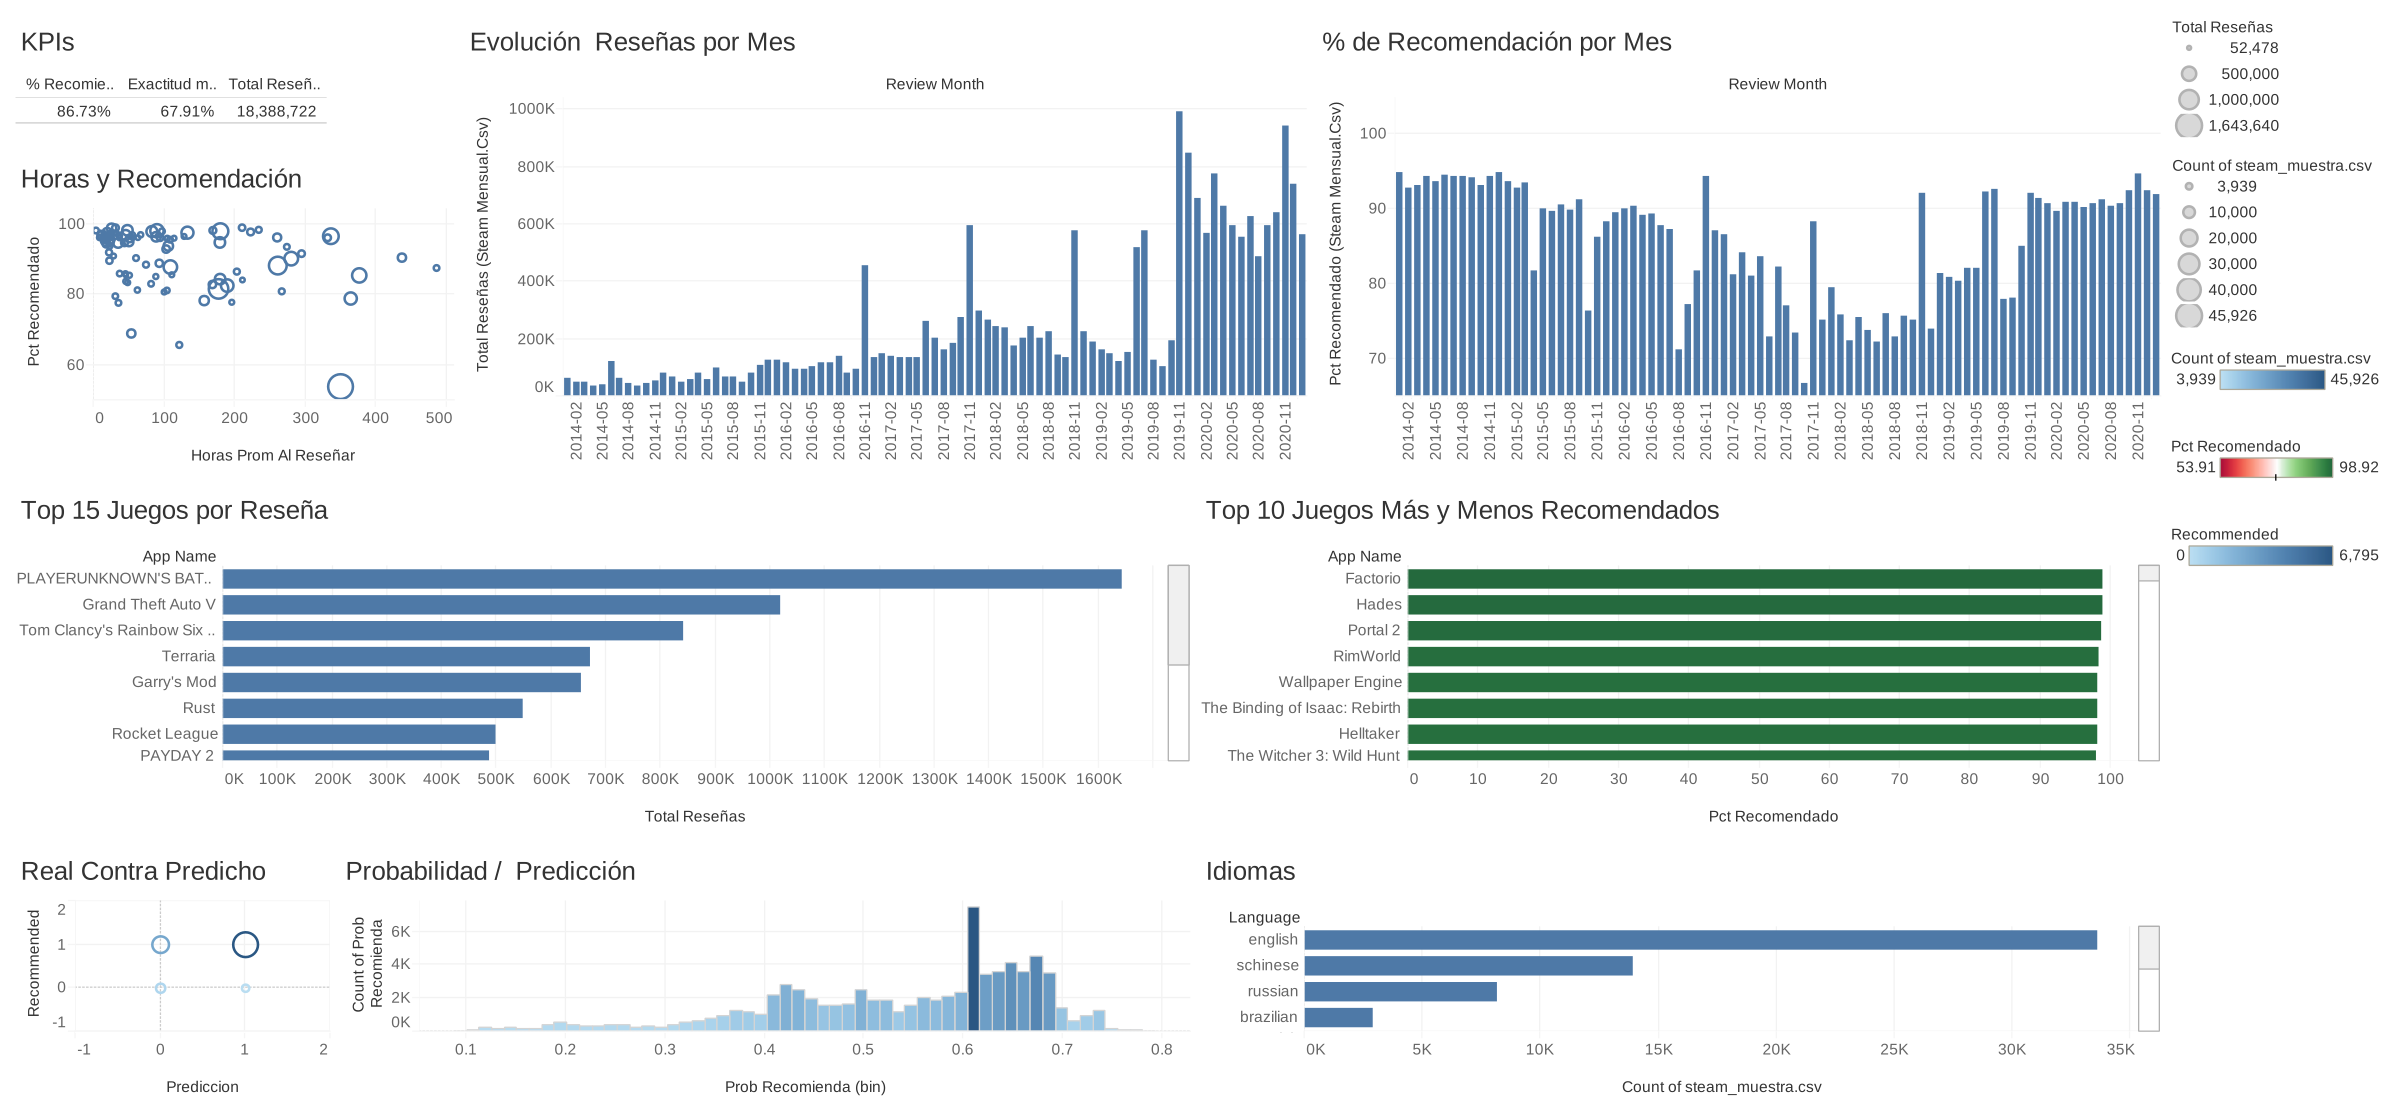

*Nota: en la versión interactiva, las gráficas "Top 15 Juegos por Reseña", "Top 10 Juegos Más y Menos Recomendados" e "Idiomas" tienen barra de desplazamiento; la captura muestra solo la parte visible.*

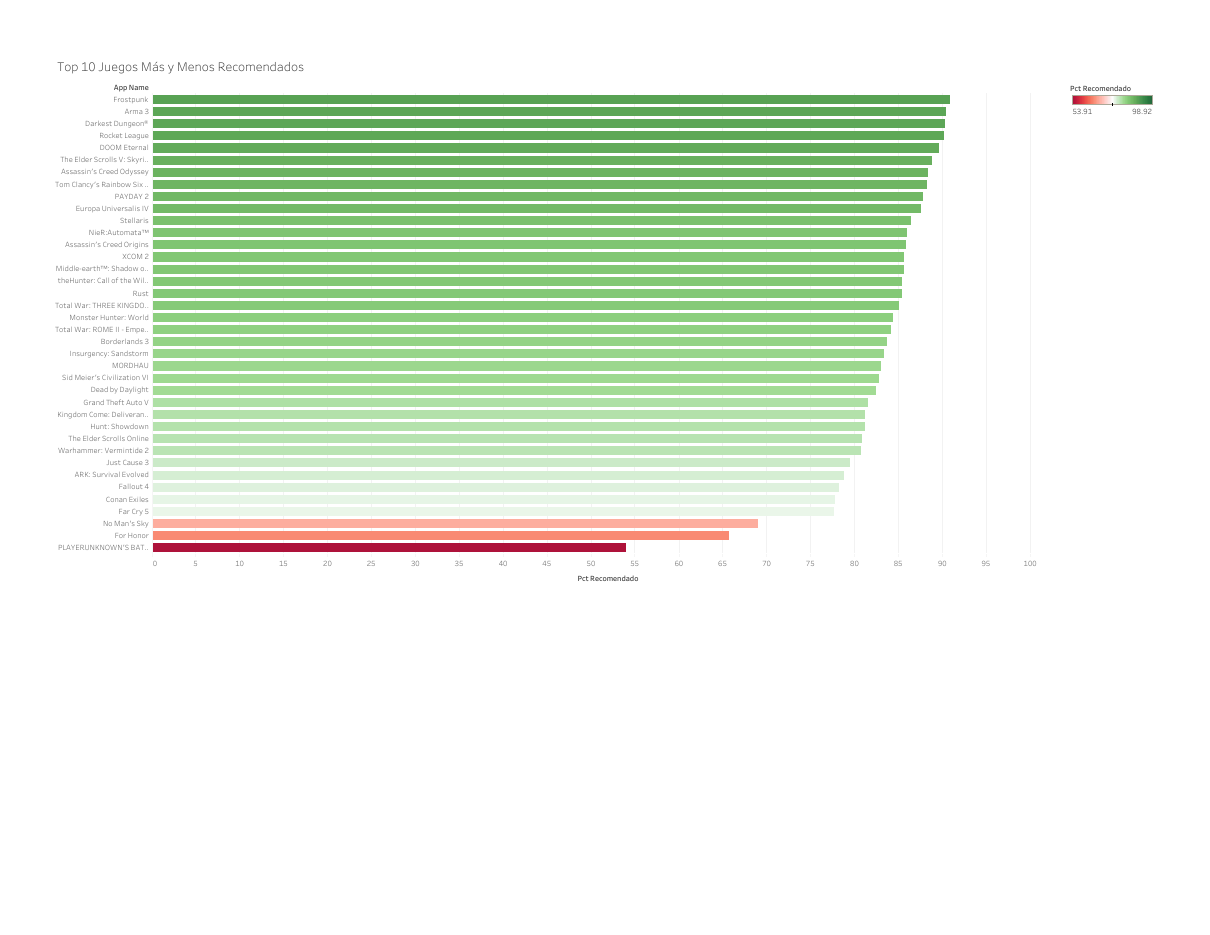

**Qué contiene el tablero:** KPIs (% de recomendación 86.73%, exactitud del modelo 67.91% y 18,388,722 reseñas, calculados sobre los datos exportados a Tableau y no sobre las 21.7 millones completas), juegos con más reseñas, juegos más y menos recomendados, evolución mensual del volumen y del % de recomendación, relación entre horas promedio y recomendación, idiomas, y tres vistas del modelo (real contra predicho, distribución de probabilidades).

**Cómo usar el tablero para tomar decisiones:**

1. **Priorizar atención por juego.** Cruzar "Top 15 por reseñas" con "Juegos más y menos recomendados" permite detectar títulos con mucho volumen y baja recomendación. PUBG (1.64 millones de reseñas, 53.9%) es el caso extremo y concentra ≈28% de las reseñas negativas; ARK (78.9%) y Fallout 4 (78.3%) le siguen en volumen. Son los candidatos para revisar primero las quejas.
2. **Planear cuándo hay más carga.** En la evolución mensual, noviembre y diciembre concentran los picos (993,108 reseñas en noviembre de 2019). Es útil para dimensionar moderación o soporte. Una caída del % mensual funciona como alerta: entre 2016 y 2018 hubo meses con 66% a 73%.
3. **Detectar juegos atípicos por tiempo de juego.** En el diagrama de horas contra recomendación, la burbuja de PUBG (≈350 h promedio y 53.9%) se aleja del resto, que se agrupa arriba (más de 85% de recomendación).
4. **Segmentar por idioma.** Después del inglés, el chino simplificado es el segundo idioma con más reseñas y recomienda menos que el promedio (77.1%), por lo que merece análisis aparte.
5. **Usar el modelo como filtro de priorización, no como decisión automática.** Las vistas de real contra predicho y de probabilidad muestran que el modelo separa solo de manera moderada (exactitud de 67.9%, por debajo del 87.5% de predecir siempre "recomienda", porque se entrenó con pesos de clase para detectar negativas; AUC-ROC de 0.713). Para alertas más precisas conviene un umbral cercano a 0.40; para no dejar escapar negativas, uno de 0.60 o más (ver 7.1, celda F).

## 8.9 Conclusiones y limitaciones

- PySpark permitió procesar más de 21 millones de reseñas de forma eficiente, y MLlib ofreció un flujo completo (Pipeline, pesos de clase, evaluación y guardado del modelo). La conversión a Parquet redujo el tamaño de los datos de 8.17 GB a 352 MB.
- El modelo tiene un desempeño modesto (AUC-ROC de 0.713 en prueba y 0.670 en juegos nuevos). La razón principal es que el sentimiento de una reseña está sobre todo en su **texto**, y el modelo solo usa su longitud y el perfil del jugador. Incorporar el texto (por ejemplo con `Tokenizer` y `HashingTF`/`IDF`) podría mejorar mucho el desempeño.
- **Calidad de datos:** `num_games_owned` y `num_reviews` contienen valores absurdos (máximos de ≈4.4 × 10¹², cercanos a 2⁴²) y `review_len` llega a más de 9 millones de caracteres. Afectan a muy pocos registros (5, 2 y 55 de 21.7 millones, según 7.1 celda A), por lo que se decidió no filtrarlos: `log1p` y los árboles limitan su efecto en el modelo. Sí invalidan las comparaciones por promedio, así que el análisis descriptivo usa medianas.
- **Posible fuga de información temporal:** `playtime_forever` incluye horas jugadas después de escribir la reseña, por lo que el modelo usa información que no existiría si se quisiera predecir antes de que el jugador reseñe. Sirve para analizar reseñas ya escritas, no para anticiparlas.
- **Tablero:** los KPIs se calculan sobre los datos exportados (muestra de predicciones, 100 juegos y 123 meses), no sobre las 21.7 millones de reseñas completas, por lo que difieren ligeramente de las cifras del notebook (por ejemplo, 86.73% frente a 87.48% de recomendación).
- El conjunto de datos corresponde a una selección de juegos y a un periodo concretos, por lo que los resultados pueden no generalizarse a toda la plataforma.
- Se entrenó con el 15% del conjunto de entrenamiento por limitaciones de memoria y tiempo en Colab; en un clúster se podría usar todo el conjunto.
- **Mejoras futuras:** crear `playtime_after_review`, usar el idioma como variable categórica en lugar de `is_english`, ajustar hiperparámetros con `CrossValidator`, probar `GBTClassifier`, ajustar el umbral de decisión, agregar género y precio del juego, y analizar el texto de las reseñas.